# ForMa: evaluation results and mask visualizations

Explore **macro localization metrics** by category and mask type, then inspect actual ForMa predictions beside their ground truth. Read results from `results/results_excel.xlsx`; the workbook is never modified.

Run cells in order using the Python environment used for ForMa evaluation. Plotting requires `pandas`, `openpyxl`, `numpy`, `matplotlib`, and `ipykernel`; sample inference also uses the existing ForMa dependencies and checkpoint. If needed, install plotting dependencies in that environment with `%pip install matplotlib pandas openpyxl ipykernel`.

Figures are exported to `results/figures/`. The last section performs inference on two samples by default and caches their binary predictions. CPU inference may take several minutes.

In [4]:
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.


c:\Users\PC CABA DZ\DRAIEVAL\Group8_Benchmarking_inpainting_detection_with_small_models\.venv\Scripts\python.exe: No module named pip


In [6]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Locate ForMa when launched from its folder, the project root, or the workspace.
FORMA_CANDIDATES = [Path.cwd(), Path.cwd() / 'ForMa',
                   Path.cwd() / 'Group8_Benchmarking_inpainting_detection_with_small_models' / 'ForMa']
FORMA_DIR = next((p.resolve() for p in FORMA_CANDIDATES
                  if (p / 'show_results.py').is_file()), None)
if FORMA_DIR is None:
    raise FileNotFoundError('Open this notebook from the ForMa folder or set FORMA_DIR explicitly.')
WORKBOOK = FORMA_DIR / 'results' / 'results_excel.xlsx'
EVALUATION_ID = None  # If multiple configurations exist, paste one full ID below.
SAVE_FIGURES = True

raw = pd.read_excel(WORKBOOK, sheet_name='images', dtype={'source_id': str})
if raw.empty:
    raise ValueError('No evaluated images in the workbook yet.')
ids = raw.evaluation_id.unique()
if EVALUATION_ID is None:
    if len(ids) != 1:
        display(raw.groupby(['evaluation_id', 'subset']).size().rename('images').to_frame())
        raise ValueError('Set EVALUATION_ID to select one configuration; do not mix configurations.')
    EVALUATION_ID = ids[0]
df = raw.loc[raw.evaluation_id == EVALUATION_ID].copy()
if df.empty:
    raise ValueError('Selected EVALUATION_ID was not found.')
FIG_DIR = FORMA_DIR / 'results' / 'figures' / EVALUATION_ID[:12]
if SAVE_FIGURES:
    FIG_DIR.mkdir(parents=True, exist_ok=True)
METRICS = ['pixel_f1', 'iou', 'precision', 'recall', 'specificity', 'pixel_accuracy']
LABELS = {'pixel_f1': 'F1 / Dice', 'iou': 'IoU', 'precision': 'Precision',
          'recall': 'Recall', 'specificity': 'Specificity', 'pixel_accuracy': 'Pixel accuracy'}
COLORS = {'bbox': '#2563eb', 'segm': '#ea580c'}
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 10})
def finish(fig, name):
    fig.tight_layout()
    if SAVE_FIGURES:
        fig.savefig(FIG_DIR / f'{name}.png', dpi=180, bbox_inches='tight')
    plt.show()

print(f'{len(df):,} images | {df.source_id.nunique()} sources | {df.category.nunique()} categories')
print(f'Evaluation: {EVALUATION_ID}')
print(f'Figures: {FIG_DIR}')
display(df.groupby(['category', 'mask_type']).size().unstack(fill_value=0).rename_axis(columns=None))
undefined = df[METRICS].isna().sum()
print('Undefined metric counts:', undefined.to_dict())

ModuleNotFoundError: No module named 'matplotlib'

## Averaging rules

Each category score is the mean of its **defined per-image scores**, combining bbox and segm examples. **All images** gives each image equal weight; **equal categories** averages category means. Mask types contribute according to their number of defined scores, so balanced data gives them equal weight. Missing scores are excluded per metric; an entirely undefined category is excluded from that metric's equal-category average.

These are macro metrics, not metrics calculated from pooled pixel counts. Dice equals F1 in this evaluator, so they appear as one metric. Related variants are not independent observations; distribution plots below are descriptive, not confidence intervals. Only evaluated samples are included.

,F1 / Dice,IoU,Precision,Recall,Specificity,Pixel accuracy
All images,0.3150,0.2259,0.4542,0.3277,0.9739,0.9316
Equal categories,0.3303,0.2366,0.4760,0.3332,0.9745,0.9309


,F1 / Dice,IoU,Precision,Recall,Specificity,Pixel accuracy
mask_type,,,,,,
bbox,0.3078,0.2113,0.5085,0.2784,0.9750,0.9170
segm,0.3223,0.2406,0.3999,0.3770,0.9727,0.9462


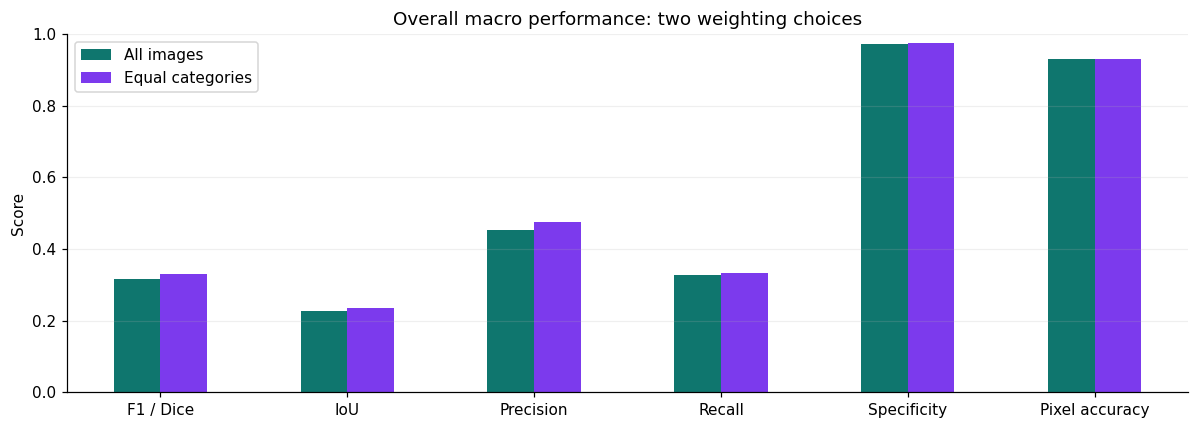

In [2]:
category_means = df.groupby('category')[METRICS].mean()
mask_means = df.groupby('mask_type')[METRICS].mean().reindex(['bbox', 'segm'])
overall = pd.DataFrame([df[METRICS].mean(), category_means.mean()],
                       index=['All images', 'Equal categories'])
display(overall.rename(columns=LABELS).round(4))
display(mask_means.rename(columns=LABELS).round(4))
fig, ax = plt.subplots(figsize=(11, 4))
overall.rename(columns=LABELS).T.plot.bar(ax=ax, color=['#0f766e', '#7c3aed'], rot=0)
ax.set(title='Overall macro performance: two weighting choices', ylabel='Score', ylim=(0, 1))
ax.grid(axis='y', alpha=.2)
finish(fig, 'overall_macro_metrics')

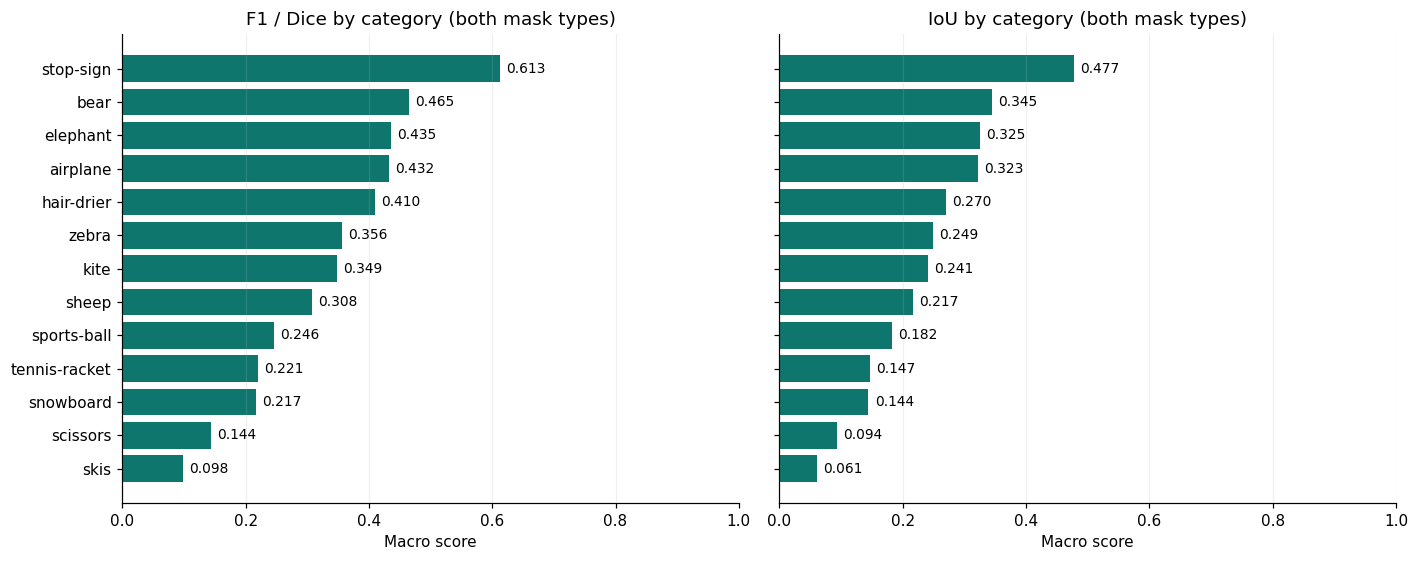

In [3]:
order = category_means.sort_values('pixel_f1').index
fig, axes = plt.subplots(1, 2, figsize=(13, max(5, len(order) * .4)), sharey=True)
for ax, metric in zip(axes, ['pixel_f1', 'iou']):
    values = category_means.loc[order, metric]
    ax.barh(order, values, color='#0f766e')
    for y, value in enumerate(values):
        if pd.notna(value):
            ax.text(value + .01, y, f'{value:.3f}', va='center', fontsize=9)
    ax.set(title=f'{LABELS[metric]} by category (both mask types)', xlabel='Macro score', xlim=(0, 1))
    ax.grid(axis='x', alpha=.2)
finish(fig, 'category_f1_iou')

## Bounding-box versus segmentation examples

Each manipulated image is scored against its own matching ground-truth mask. Bbox and segm represent different manipulated images, not interchangeable annotations for a single image. A performance difference can reflect region size, content, or generation differences as well as shape.

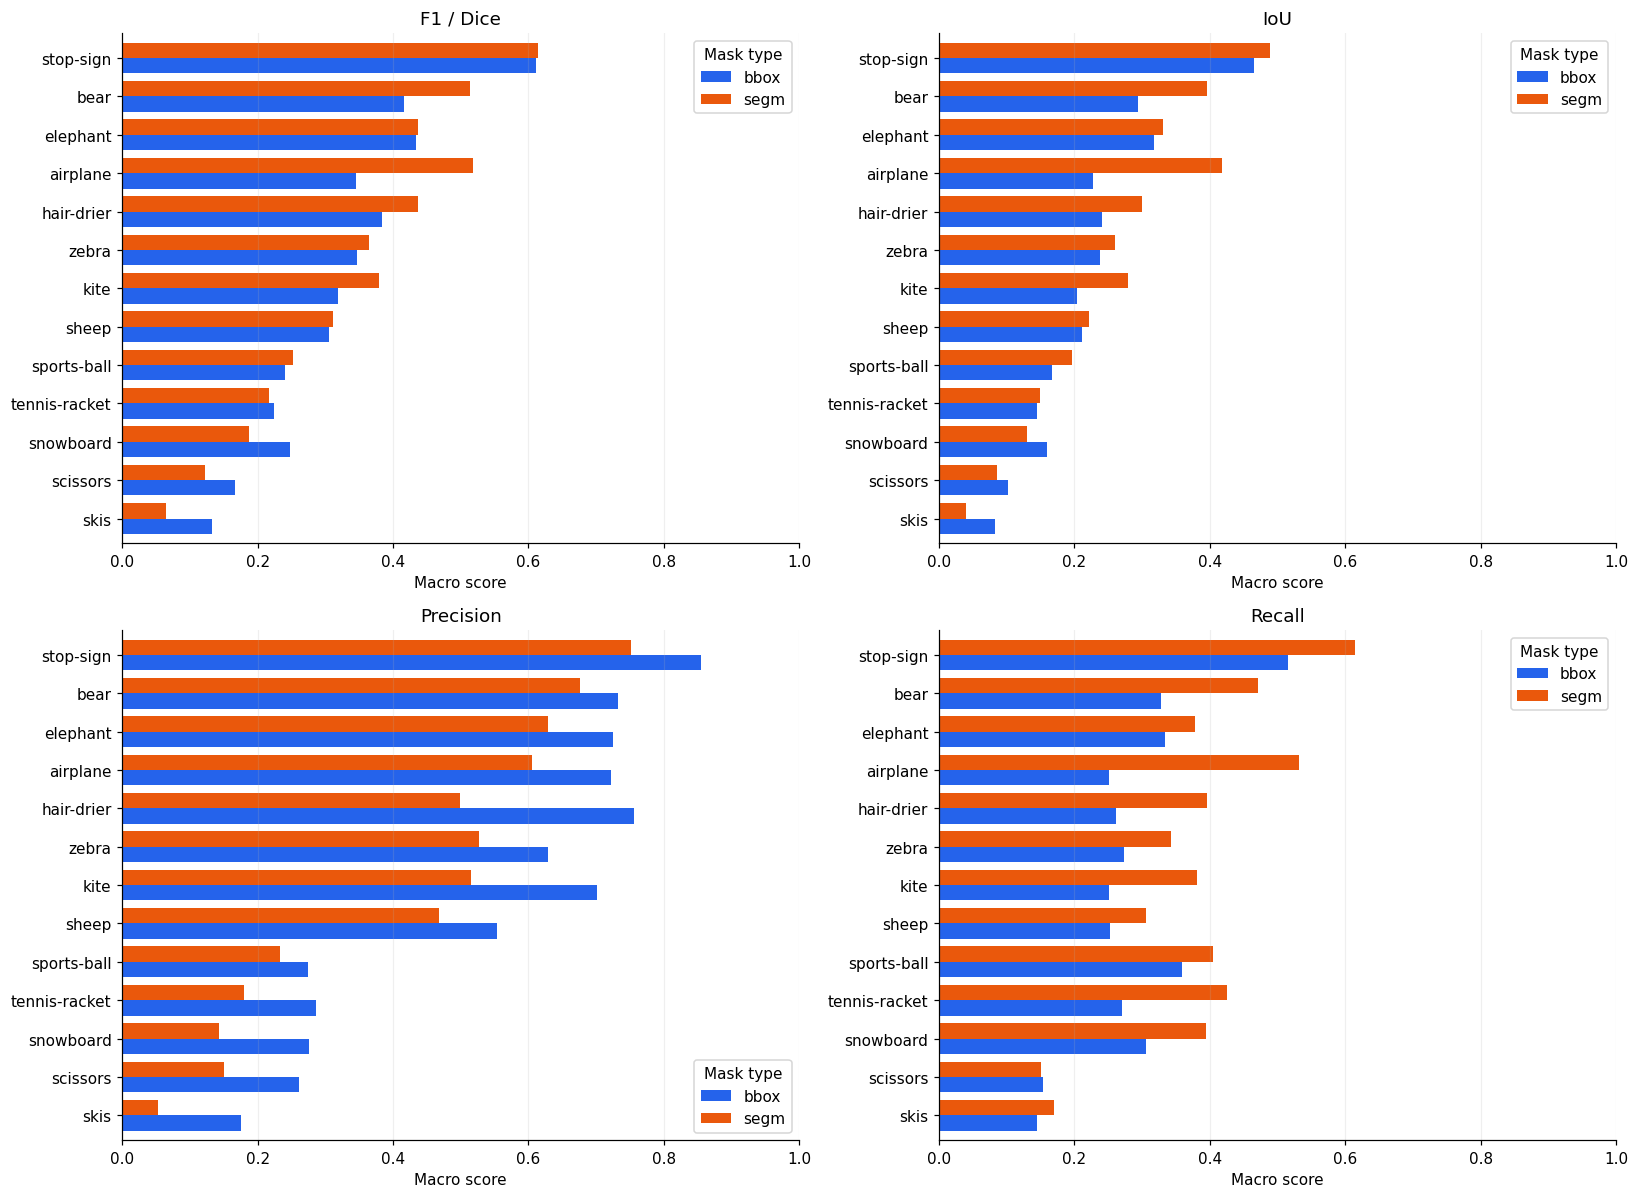

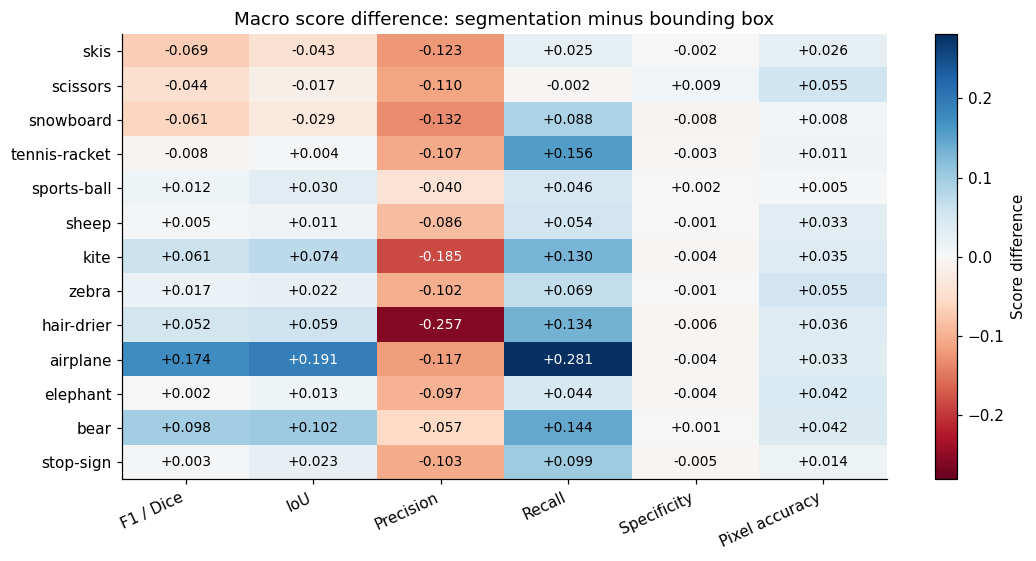

In [4]:
by_type = df.groupby(['category', 'mask_type'])[METRICS].mean()
fig, axes = plt.subplots(2, 2, figsize=(15, 11))
for ax, metric in zip(axes.flat, ['pixel_f1', 'iou', 'precision', 'recall']):
    table = by_type[metric].unstack().reindex(index=order, columns=['bbox', 'segm'])
    table.plot.barh(ax=ax, color=[COLORS['bbox'], COLORS['segm']], width=.8)
    ax.set(title=LABELS[metric], xlabel='Macro score', ylabel='', xlim=(0, 1))
    ax.grid(axis='x', alpha=.2)
    ax.legend(title='Mask type')
finish(fig, 'category_mask_type_comparison')

# Positive values mean segm scores are higher; this is descriptive, not a significance test.
delta = (by_type.xs('segm', level='mask_type') - by_type.xs('bbox', level='mask_type')).reindex(order)
fig, ax = plt.subplots(figsize=(10, max(5, len(order) * .4)))
limit = max(.01, float(np.nanmax(np.abs(delta.to_numpy()))))
im = ax.imshow(delta, cmap='RdBu', vmin=-limit, vmax=limit, aspect='auto')
ax.set_xticks(range(len(METRICS)), [LABELS[m] for m in METRICS], rotation=25, ha='right')
ax.set_yticks(range(len(order)), order)
for y in range(len(order)):
    for x in range(len(METRICS)):
        value = delta.iloc[y, x]
        ax.text(x, y, 'N/A' if pd.isna(value) else f'{value:+.3f}', ha='center', va='center',
                color='white' if pd.notna(value) and abs(value) > limit * .65 else 'black', fontsize=9)
ax.set_title('Macro score difference: segmentation minus bounding box')
fig.colorbar(im, ax=ax, label='Score difference')
finish(fig, 'mask_type_difference_heatmap')

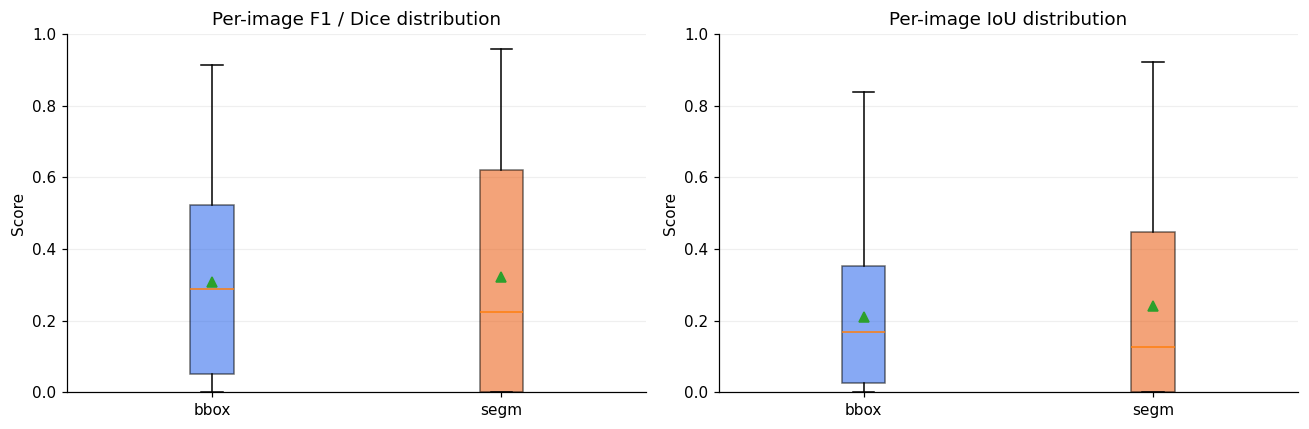

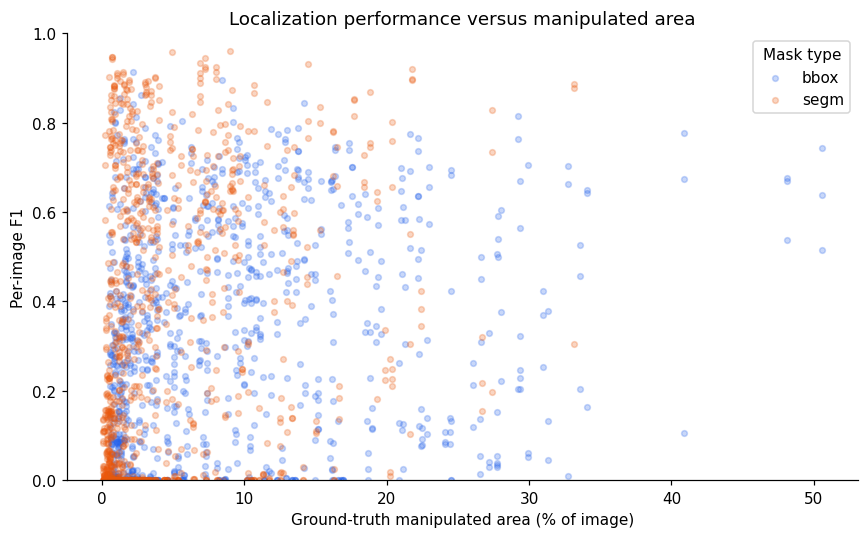

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, metric in zip(axes, ['pixel_f1', 'iou']):
    values = [df.loc[df.mask_type == kind, metric].dropna().to_numpy() for kind in ['bbox', 'segm']]
    boxes = ax.boxplot(values, patch_artist=True, showmeans=True)
    for box, color in zip(boxes['boxes'], COLORS.values()):
        box.set_facecolor(color)
        box.set_alpha(.55)
    ax.set_xticks([1, 2], ['bbox', 'segm'])
    ax.set(title=f'Per-image {LABELS[metric]} distribution', ylabel='Score', ylim=(0, 1))
    ax.grid(axis='y', alpha=.2)
finish(fig, 'per_image_score_distributions')

fig, ax = plt.subplots(figsize=(8, 5))
for kind, color in COLORS.items():
    subset = df.loc[df.mask_type == kind]
    ax.scatter(subset.foreground_fraction * 100, subset.pixel_f1,
               s=14, alpha=.25, color=color, label=kind)
ax.set(xlabel='Ground-truth manipulated area (% of image)', ylabel='Per-image F1',
       title='Localization performance versus manipulated area', ylim=(0, 1))
ax.legend(title='Mask type')
finish(fig, 'f1_vs_manipulated_area')

## Inspect images, ground truth, and actual ForMa predictions

Choose a category and source below. By default, select a source near the category's median source-average F1, and show variant 0 for both mask types. This is an illustrative selection, not a random sample or evidence of overall performance. Change `SAMPLE_SOURCE_ID` and `SAMPLE_VARIANT` to explore other cases.

The final cell uses the workbook's input size, ground-truth threshold, prediction threshold, and checkpoint hash. Input image and mask hashes are checked too. Predictions are generated with the existing inference functions and cached by sample key and inference environment. They are **recomputed predictions**, not stored masks from the original evaluation. Any discrepancy in pixel confusion counts is reported.

White means manipulated in both binary masks. The error panel uses green for true positives, red for false positives, blue for false negatives, and black for true negatives.

In [6]:
SAMPLE_CATEGORY = 'airplane'  # Any category displayed above; None selects the first.
SAMPLE_SOURCE_ID = None      # For example '5992'; None selects a median-scoring source.
SAMPLE_VARIANT = 0           # 0, 1, or 2
DEVICE = 'cpu'               # 'cpu', 'cuda', or 'auto'; cpu matches the current workbook.
WEIGHTS_OVERRIDE = None      # Optional Path to the same trusted checkpoint after relocating files.

category = SAMPLE_CATEGORY or sorted(df.category.unique())[0]
pool = df.loc[(df.category == category) & (df.variant == SAMPLE_VARIANT)]
if pool.empty:
    raise ValueError('No evaluated samples for this category and variant.')
if SAMPLE_SOURCE_ID is None:
    source_scores = pool.groupby('source_id').pixel_f1.mean().dropna().sort_values()
    if source_scores.empty:
        raise ValueError('No defined F1 scores available for automatic sample selection.')
    source_id = source_scores.index[len(source_scores) // 2]
else:
    source_id = str(SAMPLE_SOURCE_ID)
samples = pool.loc[pool.source_id == source_id].sort_values('mask_type')
if samples.empty:
    raise ValueError('Selected source is not present in this category and variant.')
if samples.mask_type.duplicated().any():
    raise ValueError('Duplicate samples for this source/variant; inspect the workbook before visualizing.')
display(samples[['category', 'source_id', 'mask_type', 'variant', 'pixel_f1', 'iou']])

,category,source_id,mask_type,variant,pixel_f1,iou
138,airplane,567432,bbox,0,0.168470,0.091983
141,airplane,567432,segm,0,0.881921,0.788783


Loading ForMa on cpu...


C:\Users\PC CABA DZ\AppData\Roaming\Python\Python310\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


C:\Users\PC CABA DZ\AppData\Roaming\Python\Python310\site-packages\timm\models\layers\__init__.py:48: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)


Can not import selective_scan_cuda_oflex. This affects speed.


C:\Users\PC CABA DZ\DRAIEVAL\Group8_Benchmarking_inpainting_detection_with_small_models\ForMa\models\csm_triton.py:23: UserWarning: Triton not installed, falling back to PyTorch implementation.
  warnings.warn(
C:\Users\PC CABA DZ\DRAIEVAL\Group8_Benchmarking_inpainting_detection_with_small_models\ForMa\models\csms6s.py:13: UserWarning: Can not import selective_scan_cuda_oflex. This affects speed.
  warnings.warn("Can not import selective_scan_cuda_oflex. This affects speed.")
C:\Users\PC CABA DZ\DRAIEVAL\Group8_Benchmarking_inpainting_detection_with_small_models\ForMa\models\csms6s.py:74: FutureWarning: `torch.cuda.amp.custom_fwd(args...)` is deprecated. Please use `torch.amp.custom_fwd(args..., device_type='cuda')` instead.
  def forward(ctx, u, delta, A, B, C, D=None, delta_bias=None, delta_softplus=False, oflex=True, backend=None):
C:\Users\PC CABA DZ\DRAIEVAL\Group8_Benchmarking_inpainting_detection_with_small_models\ForMa\models\csms6s.py:91: FutureWarning: `torch.cuda.amp.custom

['noiseprint', 'bayar', 'srm']


Predicting 567432_mask_bbox.png_ps_0.png...


Predicting 567432_mask_segm.png_ps_0.png...


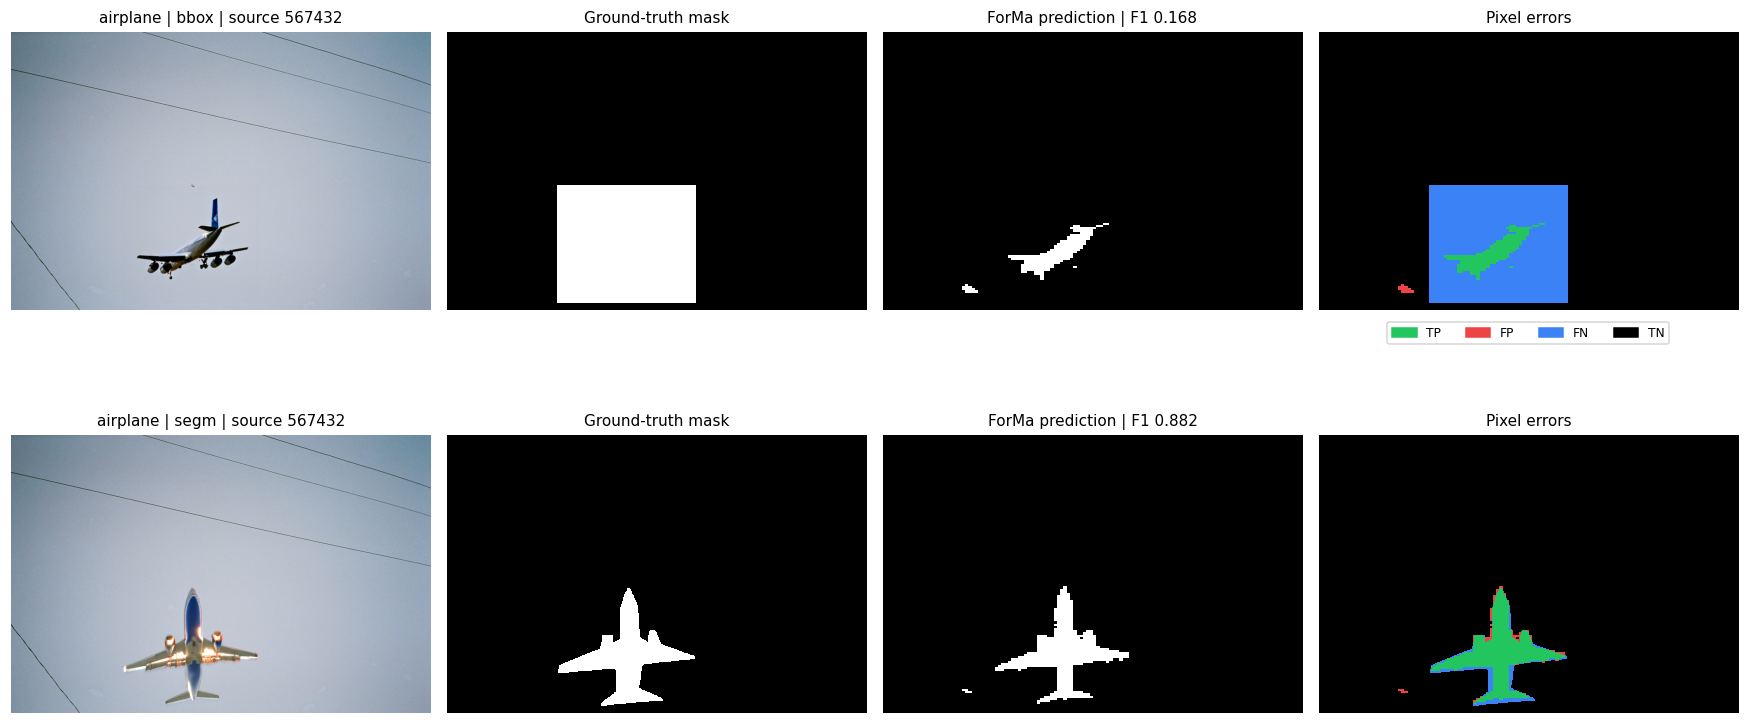

,mask_type,recorded_F1,visualized_F1,exact_counts_match
0,bbox,0.168470,0.168470,True
1,segm,0.881921,0.881921,True


In [7]:
import hashlib
import json
import torch
from PIL import Image
from matplotlib.patches import Patch

if str(FORMA_DIR) not in sys.path:
    sys.path.insert(0, str(FORMA_DIR))
from inference import load_model, preprocess_image, run_inference, prediction_maps, sha256
from metrics import localization_metrics

def resolve_sample_path(row, field):
    recorded = Path(row[field])
    if recorded.is_file():
        return recorded
    # Fallback for a copied project whose workbook contains old absolute paths.
    if field == 'image_path':
        base = FORMA_DIR / 'data_tgif' / f'{row.subset.lower()}_testing' / 'testing'
        candidates = [base / name / row.image_name for name in [row.category, row.category.replace('-', ' ')]]
    else:
        base = FORMA_DIR / 'data_tgif' / 'masks_testing' / 'testing'
        candidates = [base / name / row.mask_name for name in [row.category, row.category.replace('-', ' ')]]
    for candidate in candidates:
        if candidate.is_file():
            return candidate
    raise FileNotFoundError(f'Cannot locate {field}: {recorded}')

weights = Path(WEIGHTS_OVERRIDE) if WEIGHTS_OVERRIDE else Path(samples.iloc[0].checkpoint_path)
if not weights.is_file() and WEIGHTS_OVERRIDE is None:
    weights = FORMA_DIR / 'ForMa_weights' / 'ForMa_weights.pth'
if not weights.is_file():
    raise FileNotFoundError(f'Checkpoint missing: {weights}')
if set(samples.checkpoint_sha256) != {sha256(weights)}:
    raise ValueError('Checkpoint hash differs from the evaluated checkpoint.')
device = ('cuda' if torch.cuda.is_available() else 'cpu') if DEVICE == 'auto' else DEVICE
if device == 'cuda' and not torch.cuda.is_available():
    raise RuntimeError('CUDA is unavailable. Set DEVICE to cpu.')
torch.set_num_threads(int(samples.iloc[0].threads))
cache_dir = FORMA_DIR / 'results' / 'visualization_predictions'
cache_dir.mkdir(parents=True, exist_ok=True)
model = None
fig, axes = plt.subplots(len(samples), 4, figsize=(16, 4 * len(samples)), squeeze=False)
checks = []
for axes_row, (_, row) in zip(axes, samples.iterrows()):
    image_path = resolve_sample_path(row, 'image_path')
    mask_path = resolve_sample_path(row, 'mask_path')
    if sha256(image_path) != row.image_sha256 or sha256(mask_path) != row.mask_sha256:
        raise ValueError(f'Input files changed since evaluation: {row.image_name}')
    tensor, image = preprocess_image(image_path, int(row.input_size))
    with Image.open(mask_path) as mask_image:
        target = np.asarray(mask_image.convert('L')) > int(row.ground_truth_threshold)
    if target.shape != (image.height, image.width):
        raise ValueError(f'Mask dimensions differ: {mask_path}')
    identity = json.dumps([row.sample_key, device, str(torch.__version__), 'visualization-v1'])
    cache_path = cache_dir / (hashlib.sha256(identity.encode()).hexdigest() + '.png')
    if cache_path.is_file():
        with Image.open(cache_path) as cached:
            prediction = np.asarray(cached.convert('L')) > 127
    else:
        if model is None:
            print(f'Loading ForMa on {device}...', flush=True)
            model = load_model(weights, device)
        print(f'Predicting {row.image_name}...', flush=True)
        logits = run_inference(model, tensor.to(device))
        _, prediction = prediction_maps(logits, image.size, float(row.prediction_threshold))
        Image.fromarray(prediction.astype(np.uint8) * 255).save(cache_path)
    scores = localization_metrics(prediction, target)
    matches = all(scores[k] == int(row[k]) for k in ['tp', 'fp', 'fn', 'tn'])
    checks.append({'mask_type': row.mask_type, 'recorded_F1': row.pixel_f1,
                   'visualized_F1': scores['pixel_f1'], 'exact_counts_match': matches})
    errors = np.zeros((*target.shape, 3), dtype=np.uint8)
    errors[prediction & target] = [34, 197, 94]
    errors[prediction & ~target] = [239, 68, 68]
    errors[~prediction & target] = [59, 130, 246]
    axes_row[0].imshow(image)
    axes_row[1].imshow(target, cmap='gray', vmin=0, vmax=1, interpolation='nearest')
    axes_row[2].imshow(prediction, cmap='gray', vmin=0, vmax=1, interpolation='nearest')
    axes_row[3].imshow(errors, interpolation='nearest')
    f1_label = 'N/A' if scores['pixel_f1'] is None else f"{scores['pixel_f1']:.3f}"
    titles = [f'{row.category} | {row.mask_type} | source {row.source_id}',
              'Ground-truth mask', f'ForMa prediction | F1 {f1_label}', 'Pixel errors']
    for ax, title in zip(axes_row, titles):
        ax.set_title(title, fontsize=10)
        ax.axis('off')
axes[0, 3].legend(handles=[Patch(color=c, label=t) for c, t in
                         [('#22c55e', 'TP'), ('#ef4444', 'FP'), ('#3b82f6', 'FN'), ('black', 'TN')]],
                  loc='upper center', bbox_to_anchor=(.5, -.02), ncol=4, fontsize=8)
finish(fig, f'samples_{category}_{source_id}_variant_{SAMPLE_VARIANT}')
display(pd.DataFrame(checks))
if not all(item['exact_counts_match'] for item in checks):
    print('Some recomputed counts differ from the workbook. Check device/software differences; these panels show the recomputed outputs.')
if model is not None:
    del model
    if device == 'cuda':
        torch.cuda.empty_cache()